First 5 rows:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical Angina   
1             9     

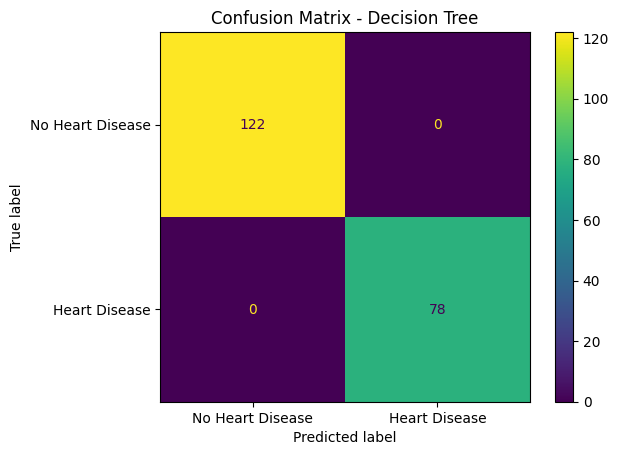

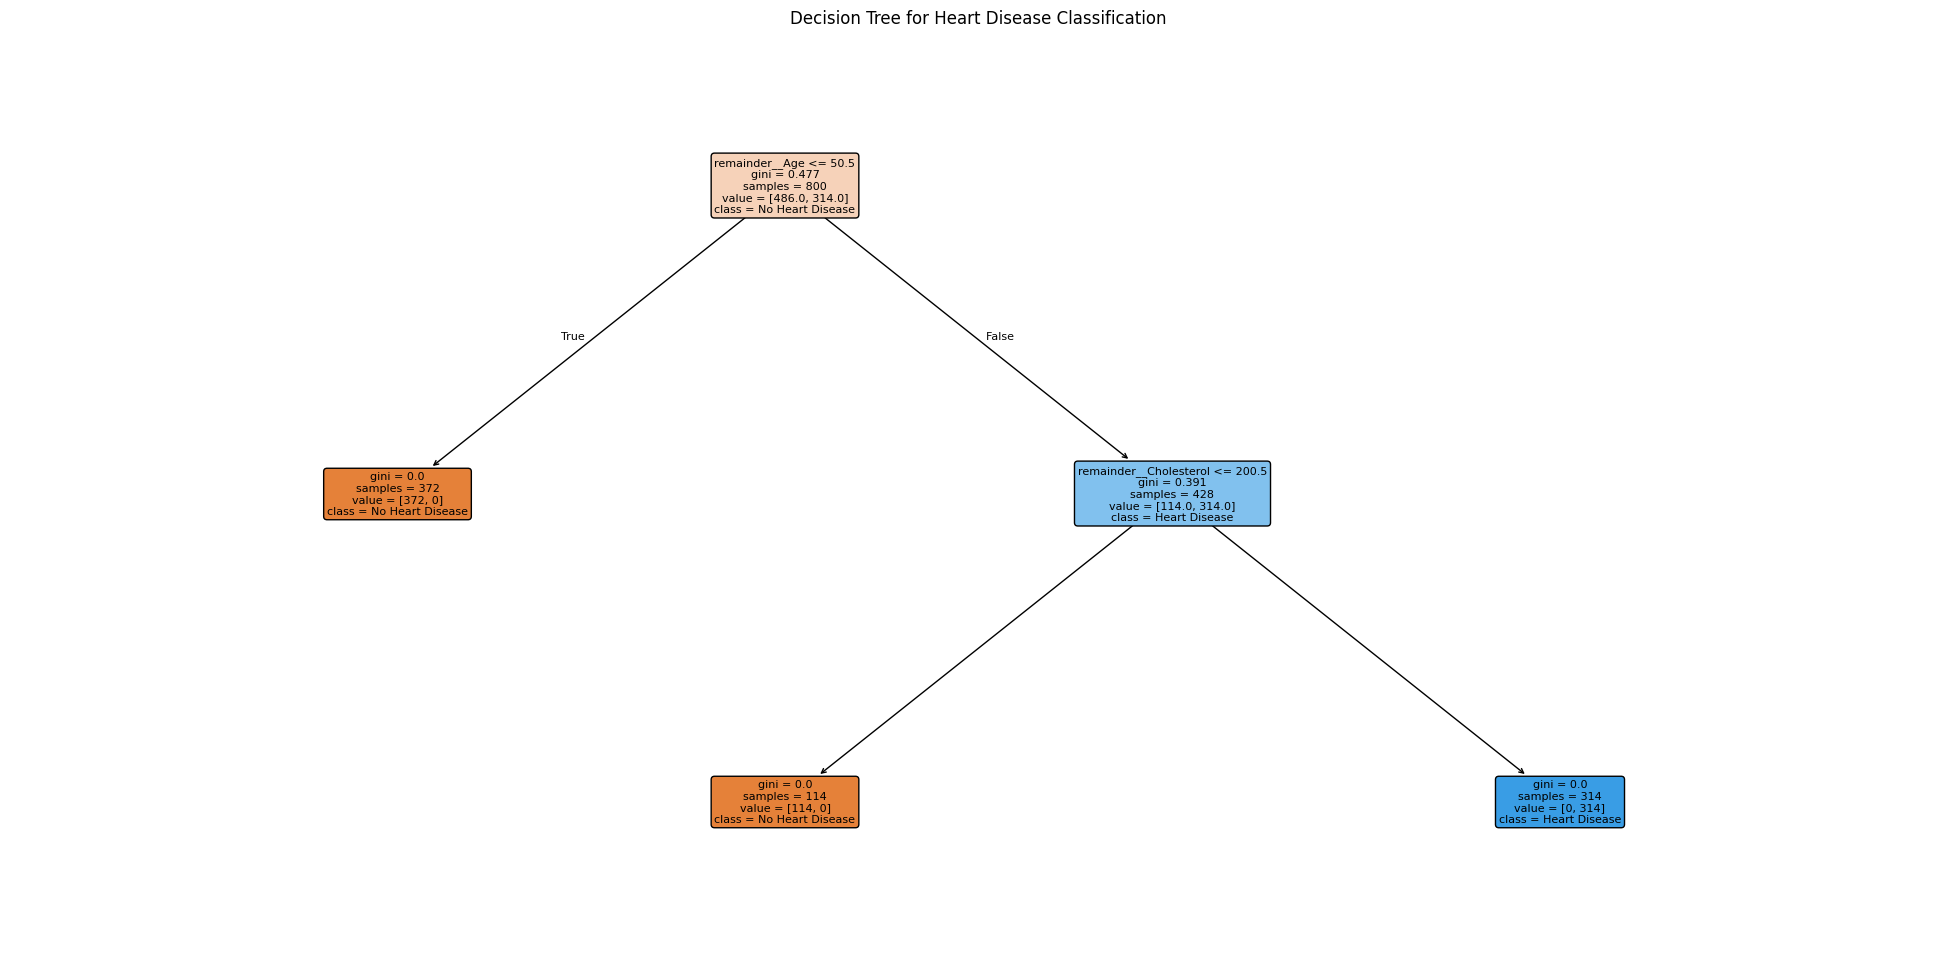

In [1]:
# EXERCISE - 08 (DECISION TREE CLASSIFICATION)

#!/usr/bin/env python
# coding: utf-8

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

df = pd.read_csv("/content/heart_disease_dataset.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

X = df.drop("Heart Disease", axis=1)
y = df["Heart Disease"]

print("\nFeatures:")
print(X.columns)

print("\nTarget:")
print(y.name)

categorical_columns = X.select_dtypes(
    include=["object"]
).columns

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns

print("\nCategorical Columns:")
print(list(categorical_columns))

print("\nNumerical Columns:")
print(list(numerical_columns))

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

decision_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", decision_tree)
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", decision_tree)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,

    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

model.fit(X_train, y_train)

print("\nDecision Tree Model Trained Successfully!")

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


print("\n==========================================")
print("       DECISION TREE EVALUATION")
print("==========================================")

print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))

# ==========================================
# 12. Classification Report
# ==========================================

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# ==========================================
# 13. Confusion Matrix
# ==========================================

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Heart Disease", "Heart Disease"]
)

disp.plot()

plt.title("Confusion Matrix - Decision Tree")
plt.show()

# Get the trained classifier
tree_model = model.named_steps["classifier"]

# Get feature names after One-Hot Encoding
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

plt.figure(figsize=(25, 12))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["No Heart Disease", "Heart Disease"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Heart Disease Classification")

plt.show()